<a href="https://colab.research.google.com/github/DeepanshuDuhan/Heart-Sync-Readmission-Predictor/blob/main/notebooks/Heart_Sync_Readmission_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install category_encoders (quiet mode)
!pip install category_encoders -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.9/85.9 kB 3.5 MB/s eta 0:00:00


In [ ]:
# Cell 2: Import all required libraries
import string
import numpy as np
import pandas as pd
import os

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)
from category_encoders import TargetEncoder
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully.")

All libraries imported successfully.


In [ ]:
# Cell 3: Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')
print("Google Drive mounted.")

Mounted at /content/drive
Google Drive mounted.


In [ ]:
# Cell 4: Define the dataset path
data_path = '/content/drive/MyDrive/Provided Tables/final_df.csv'

if not os.path.exists(data_path):
    print(f"❌ File not found: {data_path}")
    print("Please verify the path and try again.")
else:
    print(f"✅ File found at: {data_path}")

✅ File found at: /content/drive/MyDrive/Provided Tables/final_df.csv


In [ ]:
# Cell 5: Read the CSV file into a DataFrame
df = pd.read_csv(data_path)
print(f"Dataset loaded. Shape: {df.shape}")
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded. Shape: (14040, 23)

First 5 rows:


,Unnamed: 0,subject_id,hadm_id,admittime,dischtime,admission_type,discharge_location,ethnicity,cpt_cd,all_diagnosis,...,drg_type,drg_code,description,drg_severity,drg_mortality,age,next_admittime,days_to_readmit,procedure_pairs,lab_events
0,0,3,145834,2101-10-20 19:08:00,2101-10-31 13:58:00,EMERGENCY,SNF,WHITE,"['94002', '94003']","0389,78559,5849,4275,41071,4280,6826,4254,2639",...,HCFA,416.0,SEPTICEMIA AGE >17,NaN,NaN,76.0,NaN,NaN,"[(1, 9604), (2, 9962), (3, 8964), (4, 9672), (...","[(50868, '17', 'normal', 10.89), (50882, '25',..."
1,1,9,150750,2149-11-09 13:06:00,2149-11-14 10:15:00,EMERGENCY,DEAD/EXPIRED,UNKNOWN/NOT SPECIFIED,['94003'],"431,5070,4280,5849,2765,4019",...,HCFA,14.0,INTRACRANIAL HEMORRHAGE & STROKE W/ INFARCTION,NaN,NaN,41.0,NaN,NaN,"[(1, 9672), (2, 9604)]","[(50819, '5', 'normal', 0.17), (50820, '7.41',..."
2,2,21,109451,2134-09-11 12:17:00,2134-09-24 16:15:00,EMERGENCY,REHAB/DISTINCT PART HOSP,WHITE,"[99255, 99292, 99291, 99231, 90935, 99232, 909...","41071,78551,5781,5849,40391,4280,4592,5070,427...",...,APR,1744.0,Percutaneous Cardiovascular Procedures w/ AMI,4.0,4.0,87.0,NaN,NaN,"[(1, 66), (2, 3761), (3, 3950), (4, 3606), (5,...","[(51274, '15.5', 'abnormal', 9.6), (51275, '49..."
3,3,26,197661,2126-05-06 15:16:00,2126-05-13 15:00:00,EMERGENCY,HOME,UNKNOWN/NOT SPECIFIED,"[99223, 99231]","99604,4271,4280,42731,41401,412,5939,2720,60000",...,HCFA,515.0,CARDIAC DEFIBRILLATOR IMPLANT WITHOUT CARDIAC ...,NaN,NaN,72.0,NaN,NaN,"[(1, 3794), (2, 8959)]","[(51237, '1.3', 'normal', 4.44), (51248, '32.2..."
4,4,30,104557,2172-10-14 14:17:00,2172-10-19 14:37:00,URGENT,HOME HEALTH CARE,UNKNOWN/NOT SPECIFIED,NaN,"99674,4160,4111,4281,4271,41401,4019,2720,5939",...,HCFA,468.0,EXTENSIVE OPERATING ROOM PROCEDURE UNRELATED T...,NaN,NaN,NaN,NaN,NaN,"[(1, 8601), (2, 3723), (3, 8855), (4, 9227)]","[(50800, 'ART', 'normal', 4.94), (50802, '-9',..."


In [ ]:
# Cell 6: Keep only the columns needed for the model
columns_to_keep = [
    'admission_type', 'discharge_location', 'ethnicity', 'cpt_cd',
    'all_diagnosis', 'gender', 'drg_type', 'drg_code', 'description',
    'drg_severity', 'drg_mortality', 'age', 'procedure_pairs',
    'lab_events', 'days_to_readmit'
]
df = df[columns_to_keep]
print(f"Selected {len(columns_to_keep)} columns. New shape: {df.shape}")

Selected 15 columns. New shape: (14040, 15)


In [ ]:
# Cell 7: Remove rows with negative 'days_to_readmit' (data errors)
initial_rows = len(df)
df = df[(df['days_to_readmit'].isna()) | (df['days_to_readmit'] >= 0)]
print(f"Rows removed (negative days_to_readmit): {initial_rows - len(df)}")

Rows removed (negative days_to_readmit): 63


In [ ]:
# Cell 8: Create the target variable: readmission within 30 days
df['readmit_within_30'] = df['days_to_readmit'].apply(
    lambda x: 1 if pd.notna(x) and x < 30 else 0
)
print("Target variable 'readmit_within_30' created.")
print("\nClass distribution:")
print(df['readmit_within_30'].value_counts(normalize=True))

Target variable 'readmit_within_30' created.

Class distribution:
readmit_within_30
0    0.88245
1    0.11755
Name: proportion, dtype: float64


In [ ]:
# Cell 9: Drop rows with missing values in critical columns (less than 1% missing)
before_drop = len(df)
df.dropna(subset=['drg_type', 'drg_code', 'description', 'lab_events'], inplace=True)
print(f"Dropped {before_drop - len(df)} rows with missing critical values.")

Dropped 123 rows with missing critical values.


In [ ]:
# Cell 10: Fill missing text fields with placeholder strings
df['cpt_cd'] = df['cpt_cd'].fillna('no cpt_cd code')
df['procedure_pairs'] = df['procedure_pairs'].fillna('no procedure')
print("Missing text fields filled with placeholders.")

Missing text fields filled with placeholders.


In [ ]:
# Cell 11: Impute numeric columns (age, DRG severity, DRG mortality)
df['age'].fillna(df['age'].median(), inplace=True)
df['drg_mortality'].fillna(df['drg_mortality'].mode()[0], inplace=True)
df['drg_severity'].fillna(df['drg_severity'].mode()[0], inplace=True)
print("Numeric missing values imputed (median for age, mode for DRG).")
print("\nRemaining missing values:")
print(df.isnull().sum())

Numeric missing values imputed (median for age, mode for DRG).

Remaining missing values:
admission_type           0
discharge_location       0
ethnicity                0
cpt_cd                   0
all_diagnosis            0
gender                   0
drg_type                 0
drg_code                 0
description              0
drg_severity             0
drg_mortality            0
age                      0
procedure_pairs          0
lab_events               0
days_to_readmit       9643
readmit_within_30        0
dtype: int64


/tmp/ipykernel_1346/3776170070.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(df['age'].median(), inplace=True)
/tmp/ipykernel_1346/3776170070.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', tr

In [ ]:
# Cell 12: Clean text columns: lowercase and remove punctuation (except commas)
exclude = string.punctuation.replace(',', '')

def remove_punc(text):
    """Lowercase and remove punctuation except commas."""
    text = str(text).lower()
    return text.translate(str.maketrans('', '', exclude))

df['cpt_cd'] = df['cpt_cd'].apply(remove_punc)
df['all_diagnosis'] = df['all_diagnosis'].apply(remove_punc)
df['description'] = df['description'].apply(remove_punc)
df['procedure_pairs'] = df['procedure_pairs'].apply(remove_punc)
df['lab_events'] = df['lab_events'].apply(remove_punc)

print("Text columns cleaned (lowercased, punctuation removed).")

Text columns cleaned (lowercased, punctuation removed).


In [ ]:
# Cell 13: Define a custom wrapper to use TfidfVectorizer inside a ColumnTransformer
class TfidfWrapper(BaseEstimator, TransformerMixin):
    """
    Wraps TfidfVectorizer so it can be used inside a ColumnTransformer.
    """
    def __init__(self, **tfidf_kwargs):
        self.tfidf = TfidfVectorizer(**tfidf_kwargs)

    def fit(self, X, y=None):
        data = X.fillna('').astype(str).values.ravel()
        self.tfidf.fit(data)
        return self

    def transform(self, X):
        data = X.fillna('').astype(str).values.ravel()
        return self.tfidf.transform(data)

print("TfidfWrapper class defined.")

TfidfWrapper class defined.


In [ ]:
# Cell 14: Build the ColumnTransformer preprocessing pipeline
preprocessor = ColumnTransformer([
    ('admission_type', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['admission_type']),
    ('discharge_location', TargetEncoder(), ['discharge_location']),
    ('ethnicity', TargetEncoder(), ['ethnicity']),
    ('cpt_cd', TfidfWrapper(stop_words='english'), ['cpt_cd']),
    ('all_diagnosis', TfidfWrapper(stop_words='english'), ['all_diagnosis']),
    ('gender', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['gender']),
    ('drg_type', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['drg_type']),
    ('drg_code', TfidfWrapper(stop_words='english'), ['drg_code']),
    ('description', TfidfWrapper(stop_words='english'), ['description']),
    ('drg_severity', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['drg_severity']),
    ('drg_mortality', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['drg_mortality']),
    ('age', StandardScaler(), ['age']),
    ('procedure_pairs', TfidfWrapper(stop_words='english'), ['procedure_pairs']),
    ('lab_events', TfidfWrapper(stop_words='english'), ['lab_events'])
], remainder='drop', verbose_feature_names_out=False)

print("Preprocessing pipeline (ColumnTransformer) built.")
print("Transformers used: OneHot, TargetEncoder, TfidfWrapper, StandardScaler")

Preprocessing pipeline (ColumnTransformer) built.
Transformers used: OneHot, TargetEncoder, TfidfWrapper, StandardScaler


In [ ]:
# Cell 15: Create a subset containing only patients who had a readmission (days_to_readmit not null)
new_df = df[df['days_to_readmit'].notnull()].copy()
print(f"Readmitted‑only dataset size: {new_df.shape[0]} rows")
print("\nClass distribution in readmitted‑only subset:")
print(new_df['readmit_within_30'].value_counts(normalize=True))

Readmitted‑only dataset size: 4211 rows

Class distribution in readmitted‑only subset:
readmit_within_30
0    0.611731
1    0.388269
Name: proportion, dtype: float64


In [ ]:
# Cell 16: Separate the features (X) and the target (y)
X_final = new_df.drop(columns=['days_to_readmit', 'readmit_within_30'])
y_final = new_df['readmit_within_30']

print(f"Feature matrix shape: {X_final.shape}")
print(f"Target vector shape:  {y_final.shape}")

Feature matrix shape: (4211, 14)
Target vector shape:  (4211,)


In [ ]:
# Cell 17: Split the data into training and test sets (stratified by target)
X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_final,
    test_size=0.2,
    random_state=42,
    stratify=y_final
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")

Training set: 3368 samples
Test set:     843 samples


In [ ]:
# Cell 18: Assemble the final pipeline including preprocessing, PCA, and the tuned Logistic Regression
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('to_dense', FunctionTransformer(
        lambda x: x.toarray(), accept_sparse=True
    )),
    ('pca', PCA(n_components=100)),
    ('classifier', LogisticRegression(
        C=0.6194990164033582,   # best C obtained from Optuna hyperparameter tuning
        penalty='l2',
        solver='liblinear',
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

print("Final pipeline created.")
print(final_pipeline)

Final pipeline created.
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('admission_type',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['admission_type']),
                                                 ('discharge_location',
                                                  TargetEncoder(),
                                                  ['discharge_location']),
                                                 ('ethnicity', TargetEncoder(),
                                                  ['ethnicity']),
                                                 ('cpt_cd', TfidfWrapper(),
                                                  ['cpt_cd']),
                                                 ('all_diagnosis',
                                                  TfidfWrapper(

In [ ]:
# Cell 19: Train the final model on the training data
final_pipeline.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


In [ ]:
# Cell 20a: Display accuracy score as a percentage
accuracy = accuracy_score(y_test, y_pred)
accuracy_percent = accuracy * 100
print(f"Accuracy : {accuracy_percent:.2f}%")

Accuracy score: 75.56%


In [ ]:
from sklearn.metrics import classification_report

report_dict = classification_report(y_test, y_pred, output_dict=True)
report_str = classification_report(y_test, y_pred)  # still get string

filtered_report = "\n".join(
    [line for line in report_str.split('\n') if not line.strip().startswith("accuracy")]
)

print("📊 Evaluation Metrics:")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print("\nClassification Report (per class):\n")
print(filtered_report)

📊 Evaluation Metrics:
Precision: 0.5312
Recall   : 0.6514
F1 Score : 0.5852

Classification Report (per class):

              precision    recall  f1-score   support

           0       0.74      0.64      0.68       516
           1       0.53      0.65      0.59       327

   macro avg       0.64      0.64      0.63       843
weighted avg       0.66      0.64      0.65       843



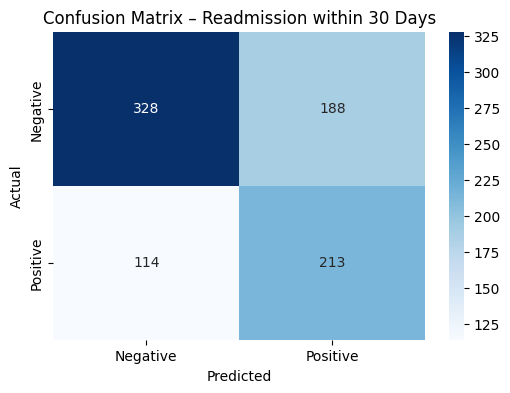

In [ ]:
# Cell 21: Visualise the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix – Readmission within 30 Days')
plt.show()

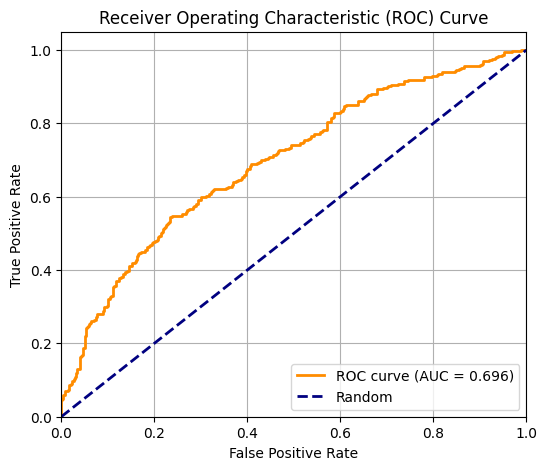

Area Under the ROC Curve (AUC): 0.6962


In [ ]:
# Cell 22: Plot the ROC curve and compute AUC
from sklearn.metrics import roc_curve, auc

# Get predicted probabilities for the positive class
y_proba = final_pipeline.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"Area Under the ROC Curve (AUC): {roc_auc:.4f}")

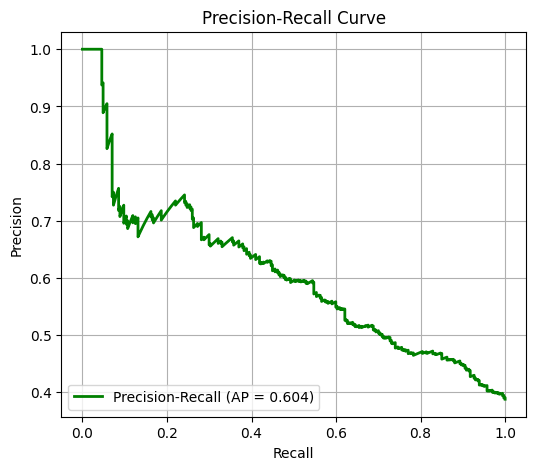

Average Precision Score (AP): 0.6043


In [ ]:
# Cell 23: Plot the Precision‑Recall curve and compute Average Precision
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_proba)
avg_precision = average_precision_score(y_test, y_proba)

plt.figure(figsize=(6, 5))
plt.plot(recall_curve, precision_curve, color='green', lw=2,
         label=f'Precision‑Recall (AP = {avg_precision:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision‑Recall Curve')
plt.legend(loc="lower left")
plt.grid(True)
plt.show()

print(f"Average Precision Score (AP): {avg_precision:.4f}")

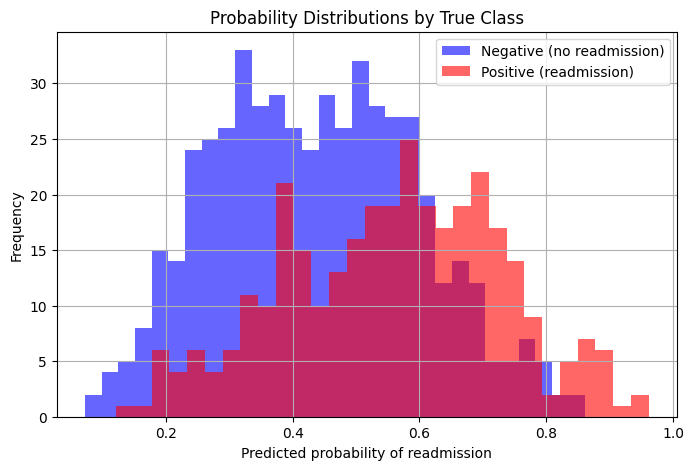

In [ ]:
# Cell 24: Distribution of predicted probabilities for negative and positive classes
y_proba_train = final_pipeline.predict_proba(X_train)[:, 1]   # for reference, optional

plt.figure(figsize=(8, 5))
plt.hist(y_proba[y_test == 0], bins=30, alpha=0.6, label='Negative (no readmission)', color='blue')
plt.hist(y_proba[y_test == 1], bins=30, alpha=0.6, label='Positive (readmission)', color='red')
plt.xlabel('Predicted probability of readmission')
plt.ylabel('Frequency')
plt.title('Probability Distributions by True Class')
plt.legend()
plt.grid(True)
plt.show()

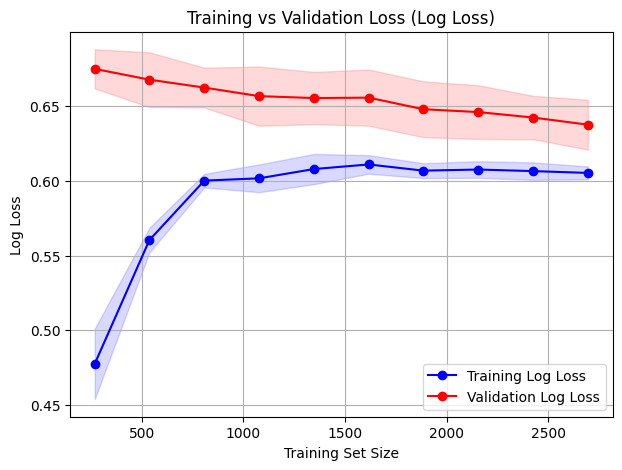

In [ ]:
# Cell 25: Training vs Validation Loss Curve (Log Loss) for different training sizes
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    final_pipeline, X_train, y_train,
    cv=5, scoring='neg_log_loss', n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10),
    random_state=42
)

# Convert negative log loss to positive log loss
train_loss = -np.mean(train_scores, axis=1)
val_loss = -np.mean(val_scores, axis=1)
train_loss_std = np.std(-train_scores, axis=1)
val_loss_std = np.std(-val_scores, axis=1)

plt.figure(figsize=(7, 5))
plt.plot(train_sizes, train_loss, 'o-', color='blue', label='Training Log Loss')
plt.fill_between(train_sizes, train_loss - train_loss_std, train_loss + train_loss_std,
                 alpha=0.15, color='blue')
plt.plot(train_sizes, val_loss, 'o-', color='red', label='Validation Log Loss')
plt.fill_between(train_sizes, val_loss - val_loss_std, val_loss + val_loss_std,
                 alpha=0.15, color='red')
plt.xlabel('Training Set Size')
plt.ylabel('Log Loss')
plt.title('Training vs Validation Loss (Log Loss)')
plt.legend(loc='best')
plt.grid(True)
plt.show()